# Mini Project 1: Numerical Pattern Predictor

**Goal:** generate numerical data that follows a hidden relationship, train a neural network to learn it,
and predict outputs for inputs the model has never seen.

**Hidden relationship used here:** `y = 2*sin(x) + 0.5*x + noise`  (the network is never told this formula).

**Steps in this notebook**
1. Imports and setup
2. Generate the data
3. Split into train / validation / test
4. Normalize the data
5. Build the model
6. Train the model
7. Plot the loss curve
8. Evaluate on the test set
9. Plot actual vs predicted
10. Predict on brand-new inputs
11. Explanation of results

## Step 1: Imports and setup

In [11]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

# Fixed seeds so your results are repeatable
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## Step 2: Generate the data

We create 1000 random inputs `x` between -5 and 5, compute the true output with a formula, and add a little
random noise to make it realistic. Shape `(1000, 1)` means 1000 rows and 1 feature per row.

x shape: torch.Size([1000, 1]) | y shape: torch.Size([1000, 1])


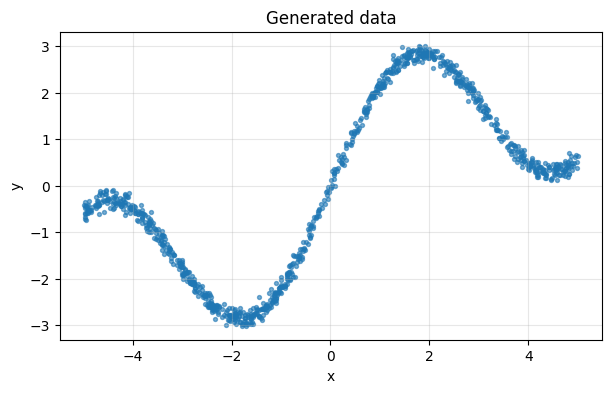

In [12]:
N = 1000
x = torch.rand(N, 1) * 10 - 5            # random values in [-5, 5]
noise = 0.1 * torch.randn(N, 1)          # small random noise
y = 2 * torch.sin(x) + 0.5 * x + noise   # the hidden pattern

print("x shape:", x.shape, "| y shape:", y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(x.numpy(), y.numpy(), s=8, alpha=0.6)
plt.title("Generated data")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(alpha=0.3)
plt.show()

## Step 3: Split into train / validation / test

- **Train (70%)**: the model learns from this.
- **Validation (15%)**: used during training to check for overfitting.
- **Test (15%)**: only used at the very end, as the final honest score.

In [13]:
idx = torch.randperm(N)
n_train = int(0.70 * N)
n_val = int(0.15 * N)

train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]

x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]

print("Train:", len(x_train), "| Validation:", len(x_val), "| Test:", len(x_test))

Train: 700 | Validation: 150 | Test: 150


## Step 4: Normalize the data

Neural networks train much more smoothly when inputs and outputs are on a similar scale.
We compute the mean and standard deviation from the **training set only**, so no information leaks from validation or test.

In [14]:
x_mean, x_std = x_train.mean(), x_train.std()
y_mean, y_std = y_train.mean(), y_train.std()

def norm_x(t): return (t - x_mean) / x_std
def norm_y(t): return (t - y_mean) / y_std
def denorm_y(t): return t * y_std + y_mean

xn_train, yn_train = norm_x(x_train), norm_y(y_train)
xn_val, yn_val = norm_x(x_val), norm_y(y_val)
xn_test, yn_test = norm_x(x_test), norm_y(y_test)

## Step 5: Build the model

A small fully connected network: 1 input -> 64 neurons -> 64 neurons -> 1 output.
ReLU activations let the network learn curves, not just straight lines.

In [15]:
model = nn.Sequential(
    nn.Linear(1, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 1),
)
print(model)

total_params = sum(p.numel() for p in model.parameters())
print("Total trainable parameters:", total_params)

Sequential(
  (0): Linear(in_features=1, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Total trainable parameters: 4353


## Step 6: Train the model

- **Loss function:** Mean Squared Error (MSE)
- **Optimizer:** Adam with learning rate 0.01
- **Batch size:** 32 samples per update
- **Epochs:** 200 full passes through the training data

In [16]:
EPOCHS = 200
BATCH_SIZE = 32
LEARNING_RATE = 0.01

train_loader = DataLoader(TensorDataset(xn_train, yn_train), batch_size=BATCH_SIZE, shuffle=True)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_losses, val_losses = [], []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        pred = model(xb)               # 1. forward pass
        loss = loss_fn(pred, yb)       # 2. compute loss
        optimizer.zero_grad()          # 3. clear old gradients
        loss.backward()                # 4. backpropagation
        optimizer.step()               # 5. update weights
        running_loss += loss.item() * xb.size(0)

    train_loss = running_loss / len(xn_train)

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(xn_val), yn_val).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1:3d}/{EPOCHS} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f}")

Epoch  20/200 | train loss: 0.0050 | val loss: 0.0065
Epoch  40/200 | train loss: 0.0043 | val loss: 0.0053
Epoch  60/200 | train loss: 0.0041 | val loss: 0.0050
Epoch  80/200 | train loss: 0.0040 | val loss: 0.0057
Epoch 100/200 | train loss: 0.0066 | val loss: 0.0070
Epoch 120/200 | train loss: 0.0035 | val loss: 0.0063
Epoch 140/200 | train loss: 0.0042 | val loss: 0.0066
Epoch 160/200 | train loss: 0.0047 | val loss: 0.0049
Epoch 180/200 | train loss: 0.0038 | val loss: 0.0049
Epoch 200/200 | train loss: 0.0038 | val loss: 0.0053


## Step 7: Plot the loss curve

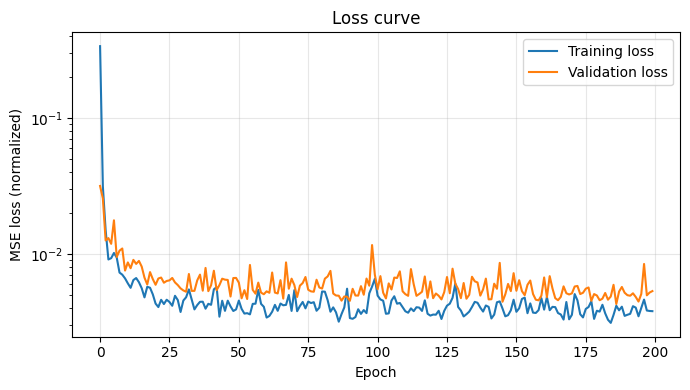

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.title("Loss curve")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (normalized)")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

## Step 8: Evaluate on the test set

The test set was never used for training or for tuning, so this is the honest measure of performance.
Predictions are converted back to the original scale before computing metrics.

In [18]:
model.eval()
with torch.no_grad():
    test_pred = denorm_y(model(xn_test))

mse = torch.mean((test_pred - y_test) ** 2).item()
mae = torch.mean(torch.abs(test_pred - y_test)).item()
ss_res = torch.sum((y_test - test_pred) ** 2)
ss_tot = torch.sum((y_test - y_test.mean()) ** 2)
r2 = (1 - ss_res / ss_tot).item()

print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R^2: {r2:.4f}")

Test MSE: 0.0164
Test MAE: 0.1020
Test R^2: 0.9947


## Step 9: Actual vs predicted graph

- **Left:** every test point. The closer to the red diagonal line, the better the prediction.
- **Right:** the data and the model's learned curve drawn over it.

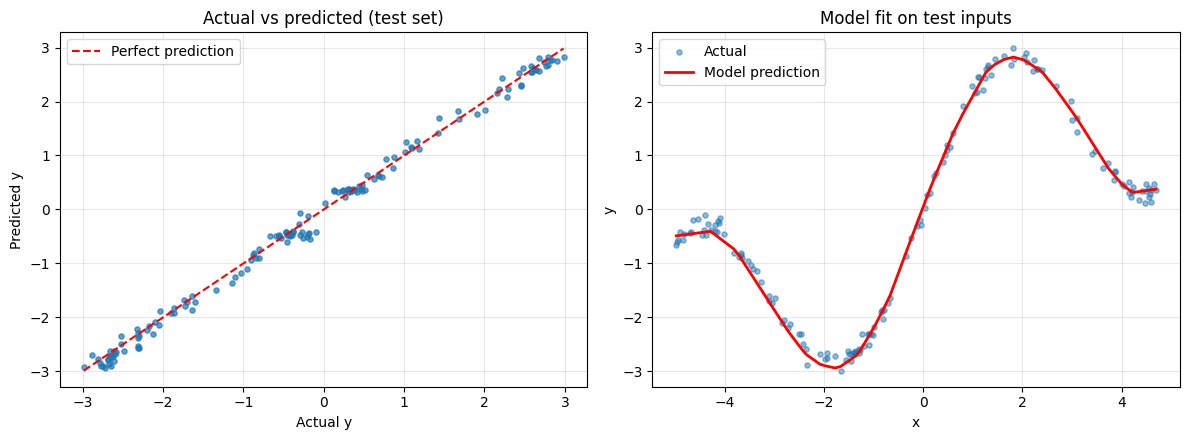

In [19]:
order = torch.argsort(x_test.squeeze())
xs = x_test[order].squeeze().numpy()
actual = y_test[order].squeeze().numpy()
predicted = test_pred[order].squeeze().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: actual vs predicted scatter
axes[0].scatter(actual, predicted, s=14, alpha=0.7)
lims = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_title("Actual vs predicted (test set)")
axes[0].set_xlabel("Actual y")
axes[0].set_ylabel("Predicted y")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: curve over the data
axes[1].scatter(xs, actual, s=14, alpha=0.5, label="Actual")
axes[1].plot(xs, predicted, "r-", linewidth=2, label="Model prediction")
axes[1].set_title("Model fit on test inputs")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

## Step 10: Predict outputs for unseen inputs

These inputs were not in the training data. We compare the model's prediction with the true value from the formula (without noise).

In [20]:
new_x = torch.tensor([[-4.5], [-2.0], [0.0], [1.5], [3.3], [4.8]])

model.eval()
with torch.no_grad():
    new_pred = denorm_y(model(norm_x(new_x)))

true_y = 2 * torch.sin(new_x) + 0.5 * new_x

print(f"{'x':>6} | {'true y':>8} | {'predicted':>10} | {'error':>8}")
print("-" * 42)
for xi, ti, pi in zip(new_x, true_y, new_pred):
    print(f"{xi.item():6.2f} | {ti.item():8.3f} | {pi.item():10.3f} | {abs(ti.item() - pi.item()):8.3f}")

     x |   true y |  predicted |    error
------------------------------------------
 -4.50 |   -0.295 |     -0.431 |    0.136
 -2.00 |   -2.819 |     -2.891 |    0.072
  0.00 |    0.000 |      0.049 |    0.049
  1.50 |    2.745 |      2.731 |    0.014
  3.30 |    1.335 |      1.392 |    0.057
  4.80 |    0.408 |      0.391 |    0.017


## Step 11: Explanation of results

**Fill in the bracketed parts with your own numbers from the outputs above.**

**What the model learned.** The data follows a hidden pattern, `y = 2*sin(x) + 0.5*x`, plus noise. The network was only shown
`(x, y)` pairs, never the formula, and learned a curve that follows the same wavy upward trend.

**Training behaviour.** Both training and validation loss dropped quickly in the first [__] epochs and then flattened.
The two curves stay close together [or: the validation loss rose above the training loss after epoch __], which means the model
[generalizes well / is starting to overfit].

**Test performance.** On data it had never seen, the model reached MSE = [__], MAE = [__] and R^2 = [__].
An R^2 close to 1 means the predictions explain almost all of the variation in the real values.
Because the data contains noise of about 0.1, a perfect score is not possible, and the model should not try to chase the noise.

**Unseen inputs.** For new inputs between -5 and 5, the predictions were within about [__] of the true values.

**Limitation.** The model only saw inputs in the range -5 to 5. Outside that range (for example x = 8) its predictions would be
unreliable, because neural networks learn the pattern in their training data rather than the underlying formula.

**Possible improvements.** Add more training data, use a deeper network, train for more epochs, or add early stopping.